# Part 4. Feature Pipeline
## FDIC bank-risk features, four-quarter outcomes and development-only preprocessing

**Input:** The Part 2 clean bank–quarter panel and separate, checksum-verified terminal-exit audit (`run_20261114T175314Z`). The Part 3 processing experiment does not alter that panel, so this stage reads the original Part 2 output directly.

**Output:** 21 current/past-only features, an audited `(q, q+4 quarters]` failure label, a four-quarter temporal purge, separate development and test-holdout Parquet inputs, and a preprocessing pipeline fitted exclusively on development observations.

**Sequence:** 1. Source and tests → 2. Part 1–2 integrity → 3. Target/split policy → 4. Build the feature dataset → 5. Inspect outcomes → 6. Inspect training-only preprocessing → 7. Verify and hand off to Part 5.

### 1. Repository, dependencies and leakage tests

The pinned environment and Git revision identify the implementation. Unit tests check date boundaries, missing reports, competing exits and publication-lag censoring. The integration tests construct an independent Parquet fixture and verify that generated features, labels and fitted preprocessing are consistent. The FDIC data are not accessed by the tests.

In [1]:
from pathlib import Path
import subprocess
import sys
import tempfile
import xml.etree.ElementTree as ET

REPOSITORY = "https://github.com/Duongnb58/BFT65B_11230945_Final.git"
REPO_DIR = Path(tempfile.mkdtemp(prefix="bft65b_part4_", dir="/content")) / "repository"
subprocess.run(["git", "clone", "--depth", "1", REPOSITORY, str(REPO_DIR)], check=True)

required = (
    "requirements_part4.txt", "run_feature_pipeline.py",
    "src/fdic_pipeline/feature_policy.py",
    "src/fdic_pipeline/feature_pipeline.py",
    "src/fdic_pipeline/panel.py",
    "tests/test_feature_policy.py",
    "tests/test_feature_pipeline_integration.py",
)
missing = [name for name in required if not (REPO_DIR / name).is_file()]
assert not missing, f"Repository files are missing: {missing}"
COMMIT_SHA = subprocess.check_output(
    ["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], text=True
).strip()
subprocess.run([
    sys.executable, "-m", "pip", "install", "-r", str(REPO_DIR / "requirements_part4.txt")
], check=True)

TEST_XML = Path("/content/bft65b_part4_tests.xml")
subprocess.run([
    sys.executable, "-m", "pytest", "-q", "-rs",
    "--junitxml", str(TEST_XML),
    str(REPO_DIR / "tests/test_feature_policy.py"),
    str(REPO_DIR / "tests/test_feature_pipeline_integration.py"),
], cwd=REPO_DIR, check=True)
suites = ET.parse(TEST_XML).getroot().findall(".//testsuite")
assert suites, "Pytest did not create a machine-readable report"
assert sum(int(s.get("skipped", 0)) for s in suites) == 0, "Integration tests were skipped"
assert sum(int(s.get("failures", 0)) + int(s.get("errors", 0)) for s in suites) == 0

sys.path.insert(0, str(REPO_DIR / "src"))
print("Part 4 tests: PASSED; skipped: 0")
print("Git commit:", COMMIT_SHA)
print("Repository:", REPO_DIR)

Part 4 tests: PASSED; skipped: 0
Git commit: 5c55612e8da1d9aa29a71848dbdfc973eb1f1eb7
Repository: /content/bft65b_part4_6aw7cll7/repository


### 2. Part 1–2 source identity

Part 4 reads the exact Part 2 run previously used in Part 3. The contract checks the Part 1 manifest hashes, the Part 2 validation status, partition inventory, record counts, availability-lag policy and the checksum of the retrospective terminal-event table. All 170 Parquet partitions are hashed again during Section 4.

In [2]:
from google.colab import drive
drive.mount("/content/drive")
from fdic_pipeline.feature_pipeline import source_contract, load_terminal_events

DRIVE_ROOT = Path("/content/drive/MyDrive/BFT65B_11230945_Final")
ACQUISITION_DIR = DRIVE_ROOT / "fdic_1984Q1_2026Q2"
PART2_RUN_ID = "run_20261114T175314Z"
PART2_DIR = DRIVE_ROOT / "data_quality_panel" / PART2_RUN_ID
SOURCE, PART2_MANIFEST = source_contract(ACQUISITION_DIR, PART2_DIR)
EVENTS = load_terminal_events(PART2_DIR, PART2_MANIFEST["source_distinct_certs"])

print("Part 1–2 source identity: PASSED")
print("Part 2 run:", SOURCE["part2_run_id"])
print("Clean panel rows:", f"{SOURCE['part2_panel_rows']:,}")
print("Source quarters:", SOURCE["part2_quarters"])
print("Terminal CERT records:", f"{len(EVENTS):,}")
print("Part 2 manifest SHA-256:", SOURCE["part2_manifest_sha256"])

Mounted at /content/drive
Part 1–2 source identity: PASSED
Part 2 run: run_20261114T175314Z
Clean panel rows: 1,682,616
Source quarters: 170
Terminal CERT records: 24,064
Part 2 manifest SHA-256: f2cab4c25cccbbcc4529c68d24baa0aae330e7a3608cef0296e6ed7c1a983782


### 3. Feature, target and temporal-split policy

Financial ratios use the current report; growth and changes use exactly the previous calendar quarter or the same quarter one year earlier. The label is one only when a documented, CERT-linked failure occurs in `(REPDTE, REPDTE + 4 quarters]`. Competing nonfailure exits and ambiguous events are not assigned negative labels. A failure occurring before the assumed report-availability date is excluded from modelling rather than claimed as predictable.

The holdout interval is fixed before estimation. All four quarters in 2007 are excluded between development and test. The years after 2014 remain outside this particular model comparison. A minimum of 50 distinct positive test certificates is verified, not used to tune models.

In [3]:
from datetime import datetime, timezone
from fdic_pipeline.feature_policy import (
    FEATURE_NAMES, DEV_END, TEST_START, TEST_END, LABEL_LAST_QUARTER,
    AVAILABILITY_LAG_DAYS, add_quarters,
)

RUN_ID = datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%SZ")
OUTPUT_DIR = DRIVE_ROOT / "feature_pipeline" / RUN_ID
assert not OUTPUT_DIR.exists(), f"Run output already exists: {OUTPUT_DIR}"
assert add_quarters(LABEL_LAST_QUARTER, 4).isoformat() == "2026-06-30"
assert DEV_END.isoformat() == "2006-12-31"
assert TEST_START.isoformat() == "2008-03-31"
print("Part 4 run:", RUN_ID)
print("Features:", len(FEATURE_NAMES))
print("Development end:", DEV_END)
print("Purged quarters: 2007Q1–2007Q4 (4 quarters)")
print("Test holdout:", TEST_START, "to", TEST_END)
print("Latest label-eligible report:", LABEL_LAST_QUARTER)
print("Assumed publication delay (days):", AVAILABILITY_LAG_DAYS)
print("Output:", OUTPUT_DIR)

Part 4 run: run_20261115T093554Z
Features: 21
Development end: 2006-12-31
Purged quarters: 2007Q1–2007Q4 (4 quarters)
Test holdout: 2008-03-31 to 2014-12-31
Latest label-eligible report: 2025-06-30
Assumed publication delay (days): 90
Output: /content/drive/MyDrive/BFT65B_11230945_Final/feature_pipeline/run_20261115T093554Z


### 4. Construct features and labels; fit preprocessing on development data

The pipeline checks each source Parquet hash/schema, processes bank histories chronologically, and creates 166 feature-table partitions (1984Q1–2025Q2). Label evidence comes only from the retrospective exit audit and is not copied into predictor columns. Development and holdout datasets are stored separately. The median-imputation/missing-indicator/robust-scaling pipeline is fitted on development rows only; the holdout is not transformed or evaluated in Part 4.

In [4]:
RUN_CMD = [
    sys.executable, str(REPO_DIR / "run_feature_pipeline.py"), "run",
    "--acquisition-dir", str(ACQUISITION_DIR),
    "--part2-dir", str(PART2_DIR),
    "--output-dir", str(OUTPUT_DIR),
    "--git-commit", COMMIT_SHA,
    "--min-test-failed-banks", "50",
]
subprocess.run(RUN_CMD, cwd=REPO_DIR, check=True)

import json
with (OUTPUT_DIR / "part4_validation.json").open(encoding="utf-8") as f:
    RESULT = json.load(f)
assert RESULT["success"] is True
assert RESULT["verified_feature_partitions"] == 166
assert RESULT["development_only_preprocessing"] is True
assert RESULT["holdout_not_evaluated"] is True
print("Part 4 feature construction: PASSED")
print("Feature table rows:", f"{RESULT['feature_rows']:,}")
print("Development rows:", f"{RESULT['development_rows']:,}")
print("Test holdout rows:", f"{RESULT['test_holdout_rows']:,}")
print("Distinct positive CERT in test:", RESULT["test_distinct_positive_certs"])

Part 4 feature construction: PASSED
Feature table rows: 1,665,087
Development rows: 1,132,341
Test holdout rows: 204,912
Distinct positive CERT in test: 510


### 5. Target accounting and audit evidence

The following values come from this run's evidence files. Positive bank-quarter labels and distinct failed certificates are different units. Unresolved or competing events remain outside supervised modelling; they are included in the full feature-table audit with a missing label.

development : {'distinct_positive_certs': 2203, 'end': '2006-12-31', 'positive_bank_quarters': 6562, 'rows': 1132341, 'start': '1984-03-31'}
purge_gap : {'end': '2007-12-31', 'quarters': 4, 'start': '2007-03-31'}
test_holdout : {'distinct_positive_certs': 510, 'end': '2014-12-31', 'evaluated_in_part4': False, 'positive_bank_quarters': 1496, 'rows': 204912, 'start': '2008-03-31'}
unused_post_test : {'end': '2025-06-30', 'start': '2015-03-31'}


**Four-quarter label eligibility**

status | rows
--- | ---
ambiguous_terminal_evidence | 13755
competing_nonfailure_exit | 48348
exit_before_assumed_publication | 14916
failure_before_assumed_publication | 2389
failure_within_4q | 8198
observed_no_failure_4q | 1576712
post_exit_report | 2
post_failure_report | 7
unresolved_before_horizon | 760

**Figure 1. Positive bank-quarter labels by temporal sample**

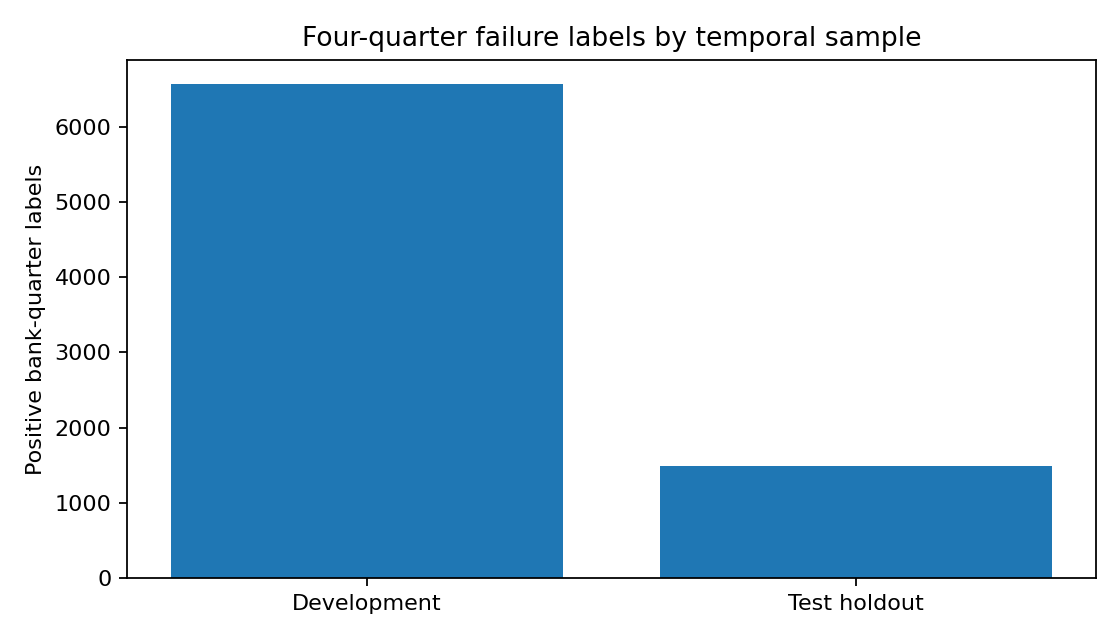

In [5]:
import csv
from IPython.display import display, Markdown, Image

def read_csv_records(path):
    with path.open(newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))

def display_md_table(title, fields, records):
    header = " | ".join(fields)
    sep = " | ".join("---" for _ in fields)
    body = "\n".join(" | ".join(str(r.get(c, "")) for c in fields) for r in records)
    display(Markdown("**" + title + "**"))
    display(Markdown(header + "\n" + sep + "\n" + body))

with (OUTPUT_DIR / "sample_summary.json").open(encoding="utf-8") as f:
    SUMMARY = json.load(f)
for name in ("development", "purge_gap", "test_holdout", "unused_post_test"):
    print(name, ":", SUMMARY[name])

labels = read_csv_records(OUTPUT_DIR / "label_status_summary.csv")
display_md_table("Four-quarter label eligibility", ["status", "rows"], labels)
display(Markdown("**Figure 1. Positive bank-quarter labels by temporal sample**"))
display(Image(filename=str(OUTPUT_DIR / "figures/labels_by_period.png"), width=680))

### 6. Development-only preprocessing and predictor whitelist

The fitted object contains a median imputer, missingness indicators and a robust scaler. Fitting uses the development Parquet partitions only. The test holdout is not passed to `fit`, `transform`, feature selection or threshold tuning. Part 5 must refit a fresh copy of this pipeline within every development-only validation fold; the stored development-fitted object is for the final development fit, not a substitute for fold-specific preprocessing.

Preprocessing fit: DEVELOPMENT ONLY
Training rows used for fit: 1,132,341
Raw predictor columns: 21
Preprocessed columns: 34
Development-all-missing features: []
Holdout transformed during Part 4: False


**Figure 2. Feature missingness in development before imputation**

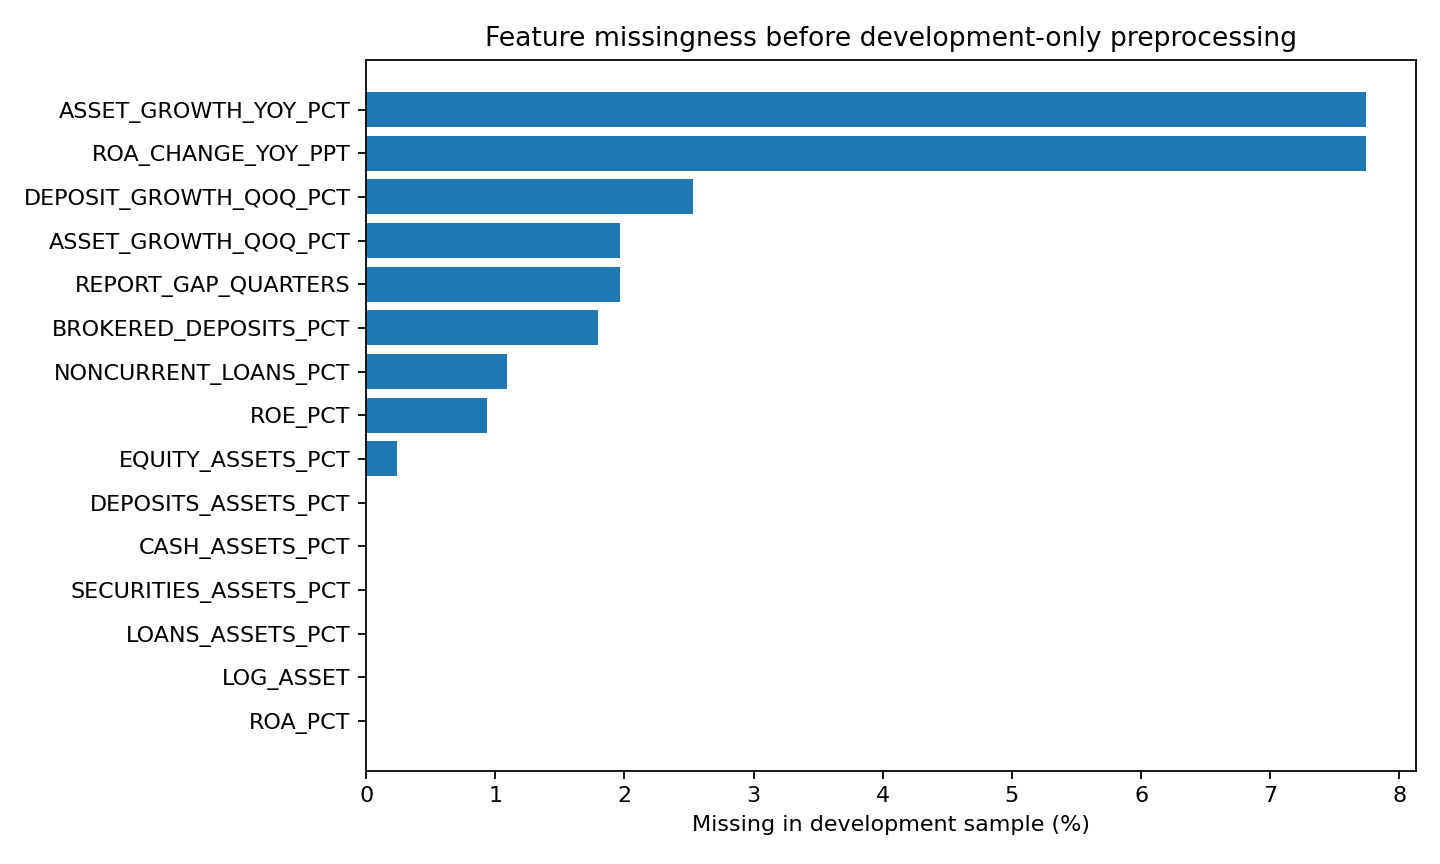

In [6]:
import pyarrow.parquet as pq
from fdic_pipeline.feature_policy import FEATURE_NAMES, LABEL_NAME
from fdic_pipeline.feature_pipeline import model_schema, feature_table_schema

with (OUTPUT_DIR / "preprocessing_fit.json").open(encoding="utf-8") as f:
    PRE = json.load(f)
assert PRE["fitted_on"] == "development_only"
assert PRE["test_holdout_transformed"] is False
assert PRE["feature_names"] == list(FEATURE_NAMES)
assert PRE["training_rows"] == RESULT["development_rows"]

first_dev = sorted((OUTPUT_DIR / "model_data/development").rglob("part-00000.parquet"))[0]
first_test = sorted((OUTPUT_DIR / "model_data/test_holdout").rglob("part-00000.parquet"))[0]
assert pq.ParquetFile(first_dev).schema_arrow == model_schema()
assert pq.ParquetFile(first_test).schema_arrow == model_schema()
assert "TERMINAL_CLASS" not in model_schema().names
assert "FAILDATE" not in model_schema().names
assert "SPLIT" not in model_schema().names
assert LABEL_NAME not in FEATURE_NAMES

print("Preprocessing fit: DEVELOPMENT ONLY")
print("Training rows used for fit:", f"{PRE['training_rows']:,}")
print("Raw predictor columns:", PRE["n_raw_features"])
print("Preprocessed columns:", PRE["n_transformed_columns"])
print("Development-all-missing features:", PRE["all_missing_in_development"])
print("Holdout transformed during Part 4:", PRE["test_holdout_transformed"])
display(Markdown("**Figure 2. Feature missingness in development before imputation**"))
display(Image(filename=str(OUTPUT_DIR / "figures/development_feature_missingness.png"), width=700))

### 7. Independent verification and Part 5 handoff

The verification command checks source lineage, every output partition's SHA-256/schema/row count, all audit files and the development-only preprocessor artifact. It does not recompute features or fit the pipeline. Part 5 should use `model_data/development/` for time-ordered validation and open `model_data/test_holdout/` only for the final single test evaluation.

In [7]:
VERIFY_CMD = [
    sys.executable, str(REPO_DIR / "run_feature_pipeline.py"), "verify",
    "--acquisition-dir", str(ACQUISITION_DIR),
    "--part2-dir", str(PART2_DIR),
    "--output-dir", str(OUTPUT_DIR),
]
subprocess.run(VERIFY_CMD, cwd=REPO_DIR, check=True)
with (OUTPUT_DIR / "part4_manifest.json").open(encoding="utf-8") as f:
    FINAL_MANIFEST = json.load(f)
assert FINAL_MANIFEST["git_commit"] == COMMIT_SHA
assert FINAL_MANIFEST["policy"]["test_used_for_preprocessing"] is False
assert FINAL_MANIFEST["policy"]["gap_quarters"] == 4
print("Part 4 evidence: PASSED")
print("Run ID:", RUN_ID)
print("Feature table:", OUTPUT_DIR / "feature_table")
print("Development model input:", OUTPUT_DIR / "model_data/development")
print("Sealed test holdout:", OUTPUT_DIR / "model_data/test_holdout")
print("Development-fitted transformer:", OUTPUT_DIR / "training_preprocessor.joblib")
print("Evidence manifest:", OUTPUT_DIR / "part4_manifest.json")
print("Git revision:", COMMIT_SHA)

Part 4 evidence: PASSED
Run ID: run_20261115T093554Z
Feature table: /content/drive/MyDrive/BFT65B_11230945_Final/feature_pipeline/run_20261115T093554Z/feature_table
Development model input: /content/drive/MyDrive/BFT65B_11230945_Final/feature_pipeline/run_20261115T093554Z/model_data/development
Sealed test holdout: /content/drive/MyDrive/BFT65B_11230945_Final/feature_pipeline/run_20261115T093554Z/model_data/test_holdout
Development-fitted transformer: /content/drive/MyDrive/BFT65B_11230945_Final/feature_pipeline/run_20261115T093554Z/training_preprocessor.joblib
Evidence manifest: /content/drive/MyDrive/BFT65B_11230945_Final/feature_pipeline/run_20261115T093554Z/part4_manifest.json
Git revision: 5c55612e8da1d9aa29a71848dbdfc973eb1f1eb7


## Part 5 interface and limitations

The four-quarter label definition follows the exam. A reported quarter is included only if its outcome horizon is complete by 2026Q2; the last eligible report is 2025Q2. Events or nonfailure exits before the **assumed** 90-day report-availability date are censored. The actual historical public-release timestamp is not available, so full publication-vintage point-in-time correctness cannot be asserted. Missing-CERT failure events remain unlinkable by certificate.

Use the fixed development/holdout split in Part 5 unless a change is explicitly documented and justified **before** fitting or evaluating models. The 2007 purge prevents four-quarter development outcome windows from overlapping the 2008 holdout start. Test performance must be measured only once after model, feature-selection and threshold decisions are complete.